In [3]:
import nltk
from nltk.tokenize import word_tokenize
from nltk.stem import PorterStemmer, WordNetLemmatizer
from nltk.corpus import stopwords
import re
import pandas as pd

In [4]:
data = pd.read_csv("../assets/tripadvisor_hotel_reviews.csv")
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 109 entries, 0 to 108
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   Review  109 non-null    str  
 1   Rating  109 non-null    int64
dtypes: int64(1), str(1)
memory usage: 1.8 KB


### Data reading and Visualization Section

In [3]:
sorted_data = data.sort_values('Rating', ascending=True)
sorted_data['Review'][1]

'ok nothing special charge diamond member hilton decided chain shot 20th anniversary seattle, start booked suite paid extra website description not, suite bedroom bathroom standard hotel room, took printed reservation desk showed said things like tv couch ect desk clerk told oh mixed suites description kimpton website sorry free breakfast, got kidding, embassy suits sitting room bathroom bedroom unlike kimpton calls suite, 5 day stay offer correct false advertising, send kimpton preferred guest website email asking failure provide suite advertised website reservation description furnished hard copy reservation printout website desk manager duty did not reply solution, send email trip guest survey did not follow email mail, guess tell concerned guest.the staff ranged indifferent not helpful, asked desk good breakfast spots neighborhood hood told no hotels, gee best breakfast spots seattle 1/2 block away convenient hotel does not know exist, arrived late night 11 pm inside run bellman bu

### Data Pre-processing Section

In [4]:
data['review_lowercase'] = data['Review'].str.lower()
data.head()

,Review,Rating,review_lowercase
0,nice hotel expensive parking got good deal sta...,4,nice hotel expensive parking got good deal sta...
1,ok nothing special charge diamond member hilto...,2,ok nothing special charge diamond member hilto...
2,nice rooms not 4* experience hotel monaco seat...,3,nice rooms not 4* experience hotel monaco seat...
3,"unique, great stay, wonderful time hotel monac...",5,"unique, great stay, wonderful time hotel monac..."
4,"great stay great stay, went seahawk game aweso...",5,"great stay great stay, went seahawk game aweso..."


In [5]:
en_stopwords = stopwords.words('english')
en_stopwords.remove("not")

In [6]:
data['review_no_stopwords'] = data['review_lowercase'].apply(lambda x: ' '.join([word for word in x.split() if word not in en_stopwords]))
data['review_no_stopwords'][0]

'nice hotel expensive parking got good deal stay hotel anniversary, arrived late evening took advice previous reviews valet parking, check quick easy, little disappointed non-existent view room room clean nice size, bed comfortable woke stiff neck high pillows, not soundproof like heard music room night morning loud bangs doors opening closing hear people talking hallway, maybe noisy neighbors, aveda bath products nice, not goldfish stay nice touch taken advantage staying longer, location great walking distance shopping, overall nice experience pay 40 parking night,'

In [7]:
data['review_no_stopwords_no_punct'] = data.apply(lambda x: re.sub(r"[*]", "star", x["review_no_stopwords"]), axis=1)
data['review_no_stopwords_no_punct'] = data.apply(lambda x: re.sub(r"([^\w\s])", "", x['review_no_stopwords_no_punct']),axis=1)
data.head()

,Review,Rating,review_lowercase,review_no_stopwords,review_no_stopwords_no_punct
0,nice hotel expensive parking got good deal sta...,4,nice hotel expensive parking got good deal sta...,nice hotel expensive parking got good deal sta...,nice hotel expensive parking got good deal sta...
1,ok nothing special charge diamond member hilto...,2,ok nothing special charge diamond member hilto...,ok nothing special charge diamond member hilto...,ok nothing special charge diamond member hilto...
2,nice rooms not 4* experience hotel monaco seat...,3,nice rooms not 4* experience hotel monaco seat...,nice rooms not 4* experience hotel monaco seat...,nice rooms not 4star experience hotel monaco s...
3,"unique, great stay, wonderful time hotel monac...",5,"unique, great stay, wonderful time hotel monac...","unique, great stay, wonderful time hotel monac...",unique great stay wonderful time hotel monaco ...
4,"great stay great stay, went seahawk game aweso...",5,"great stay great stay, went seahawk game aweso...","great stay great stay, went seahawk game aweso...",great stay great stay went seahawk game awesom...


### Tokenization

In [8]:
data['tokenized']= data.apply(lambda x: word_tokenize(x['review_no_stopwords_no_punct']), axis=1)
data['raw_tokenized'] = data.apply(lambda x: word_tokenize(x['review_lowercase']), axis=1)
data['raw_tokenized'][0]

['nice',
 'hotel',
 'expensive',
 'parking',
 'got',
 'good',
 'deal',
 'stay',
 'hotel',
 'anniversary',
 ',',
 'arrived',
 'late',
 'evening',
 'took',
 'advice',
 'previous',
 'reviews',
 'did',
 'valet',
 'parking',
 ',',
 'check',
 'quick',
 'easy',
 ',',
 'little',
 'disappointed',
 'non-existent',
 'view',
 'room',
 'room',
 'clean',
 'nice',
 'size',
 ',',
 'bed',
 'comfortable',
 'woke',
 'stiff',
 'neck',
 'high',
 'pillows',
 ',',
 'not',
 'soundproof',
 'like',
 'heard',
 'music',
 'room',
 'night',
 'morning',
 'loud',
 'bangs',
 'doors',
 'opening',
 'closing',
 'hear',
 'people',
 'talking',
 'hallway',
 ',',
 'maybe',
 'just',
 'noisy',
 'neighbors',
 ',',
 'aveda',
 'bath',
 'products',
 'nice',
 ',',
 'did',
 'not',
 'goldfish',
 'stay',
 'nice',
 'touch',
 'taken',
 'advantage',
 'staying',
 'longer',
 ',',
 'location',
 'great',
 'walking',
 'distance',
 'shopping',
 ',',
 'overall',
 'nice',
 'experience',
 'having',
 'pay',
 '40',
 'parking',
 'night',
 ',']

### Stemming & Lemmatising

In [9]:
ps = PorterStemmer()
lm = WordNetLemmatizer()
data['stemmed'] = data['tokenized'].apply(lambda string: [ps.stem(token) for token in string])
data['lemmatised'] = data['tokenized'].apply(lambda string: [lm.lemmatize(token) for token in string])

print(data['stemmed'][0], "\n\n", data['lemmatised'][0], "\n\n", data['Rating'][0])

['nice', 'hotel', 'expens', 'park', 'got', 'good', 'deal', 'stay', 'hotel', 'anniversari', 'arriv', 'late', 'even', 'took', 'advic', 'previou', 'review', 'valet', 'park', 'check', 'quick', 'easi', 'littl', 'disappoint', 'nonexist', 'view', 'room', 'room', 'clean', 'nice', 'size', 'bed', 'comfort', 'woke', 'stiff', 'neck', 'high', 'pillow', 'not', 'soundproof', 'like', 'heard', 'music', 'room', 'night', 'morn', 'loud', 'bang', 'door', 'open', 'close', 'hear', 'peopl', 'talk', 'hallway', 'mayb', 'noisi', 'neighbor', 'aveda', 'bath', 'product', 'nice', 'not', 'goldfish', 'stay', 'nice', 'touch', 'taken', 'advantag', 'stay', 'longer', 'locat', 'great', 'walk', 'distanc', 'shop', 'overal', 'nice', 'experi', 'pay', '40', 'park', 'night'] 

 ['nice', 'hotel', 'expensive', 'parking', 'got', 'good', 'deal', 'stay', 'hotel', 'anniversary', 'arrived', 'late', 'evening', 'took', 'advice', 'previous', 'review', 'valet', 'parking', 'check', 'quick', 'easy', 'little', 'disappointed', 'nonexistent', '

In [10]:
total = 0
for tokens in data['lemmatised']:
    total+=len(tokens)
print(total,"\n")

tokens_clean = sum(data['lemmatised'],[])
tokens_raw = sum(data['raw_tokenized'],[])

9407 



### N-Grams

In [11]:
unigrams = (pd.Series(nltk.ngrams(tokens_clean, 1)).value_counts())
print(unigrams[:15])

bigrams = (pd.Series(nltk.ngrams(tokens_clean, 2)).value_counts())
print(bigrams[:15])

(hotel,)       292
(room,)        275
(great,)       126
(not,)         122
(stay,)         95
(staff,)        90
(nt,)           81
(seattle,)      79
(location,)     78
(good,)         76
(nice,)         70
(night,)        69
(bed,)          68
(desk,)         59
(place,)        54
Name: count, dtype: int64
(great, location)      24
(space, needle)        21
(hotel, monaco)        16
(staff, friendly)      12
(pike, place)          12
(great, hotel)         12
(great, view)          12
(location, great)      10
(walking, distance)    10
(staff, helpful)        9
(pike, market)          9
(king, bed)             9
(hotel, great)          9
(nice, hotel)           8
(stay, hotel)           8
Name: count, dtype: int64


Text(0.5, 1.0, '10 most frequently occuring bigrams')

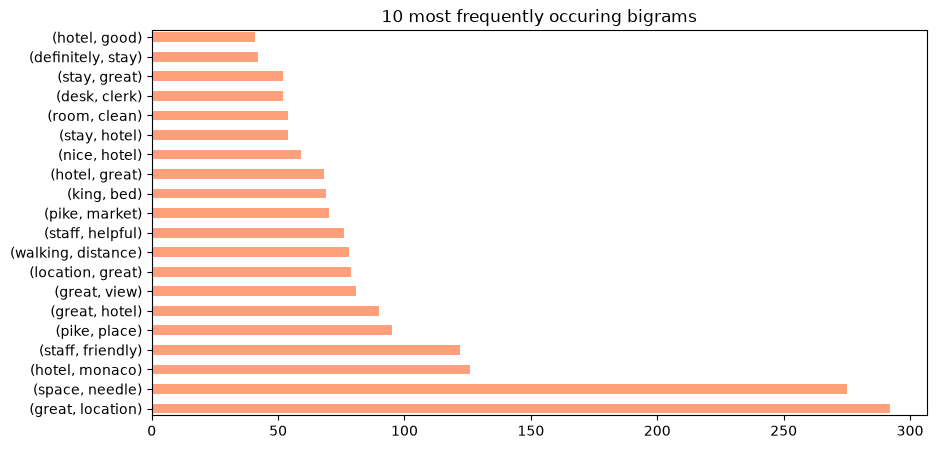

In [12]:
import matplotlib.pyplot as plt
unigrams[:20].plot.barh(color="lightsalmon", width=.5, figsize=(10,5))
plt.title("10 most frequently occuring unigrams")

bigrams[:20].plot.barh(color="lightsalmon", width=.2, figsize=(10,5))
plt.title("10 most frequently occuring bigrams")

### POS Tagging

In [13]:
import spacy
nlp = spacy.load('en_core_web_sm')

In [14]:
spacy_doc = nlp(' '.join(tokens))
for word in spacy_doc:
    print(word.text, "-", word.pos_)

lovely - ADJ
hotel - NOUN
great - ADJ
location - NOUN
stayed - VERB
vacation - NOUN
touring - NOUN
asia - PROPN
thought - VERB
raffle - PROPN
plaza - PROPN
looking - VERB
decorated - VERB
maintained - VERB
staff - NOUN
professional - ADJ
large - ADJ
room - NOUN
nice - ADJ
extra - ADJ
bathroom - NOUN
toiletry - NOUN
robe - NOUN
slipper - NOUN
walk - VERB
right - ADJ
hotel - NOUN
store - NOUN
restaurant - NOUN
huge - ADJ
mall - NOUN
hotel - NOUN
connected - VERB
good - ADJ
food - NOUN
raffle - NOUN
hotel - NOUN
right - ADJ
street - NOUN


In [15]:
pos_df = pd.DataFrame(columns=['token','pos_tag'])
for token in spacy_doc:
    pos_df = pd.concat([pos_df,
                        pd.DataFrame.from_records([{
                            'token': token.text,
                            'pos_tag': token.pos_
                        }])], ignore_index=True)
pos_df_count = pos_df.groupby(['token', 'pos_tag']).size().reset_index(name='counts').sort_values(by='counts', ascending=False)
# print(pos_df_count)

pos_df_poscounts = pos_df_count.groupby(['pos_tag'])['token'].count().sort_values(ascending=False)
print(pos_df_poscounts)

pos_tag
NOUN     16
ADJ       9
VERB      7
PROPN     3
Name: token, dtype: int64


In [16]:
nouns = pos_df_count[pos_df_count.pos_tag == 'NOUN']
print(nouns)

adjectives = pos_df_count[pos_df_count.pos_tag == 'ADJ']
print(adjectives)

         token pos_tag  counts
8        hotel    NOUN       4
26       staff    NOUN       1
21  restaurant    NOUN       1
23        robe    NOUN       1
24        room    NOUN       1
25     slipper    NOUN       1
28       store    NOUN       1
29      street    NOUN       1
31    toiletry    NOUN       1
32     touring    NOUN       1
33    vacation    NOUN       1
19      raffle    NOUN       1
1     bathroom    NOUN       1
15        mall    NOUN       1
11    location    NOUN       1
5         food    NOUN       1
           token pos_tag  counts
22         right     ADJ       2
18  professional     ADJ       1
16          nice     ADJ       1
13        lovely     ADJ       1
10         large     ADJ       1
9           huge     ADJ       1
7          great     ADJ       1
6           good     ADJ       1
4          extra     ADJ       1


In [17]:
ner_df = pd.DataFrame(columns=['token','ner_tag'])
for token in spacy_doc.ents:
    if pd.isna(token.label_) is False:
        ner_df = pd.concat([ner_df,
                            pd.DataFrame.from_records([{
                                'token': token.text,
                                'ner_tag': token.label_
                            }])], ignore_index=True)
ner_df.head()

,token,ner_tag
0,asia,LOC


## Sentiment Analysis

In [ ]:
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
import transformers
from transformers import pipeline
import matplotlib.pyplot as plt

/Users/souvikmaji/Desktop/Projects/AI/Course/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [4]:
data2 = pd.read_csv("../assets/tripadvisor_hotel_reviews.csv")
data2.head()

,Review,Rating
0,nice hotel expensive parking got good deal sta...,4
1,ok nothing special charge diamond member hilto...,2
2,nice rooms not 4* experience hotel monaco seat...,3
3,"unique, great stay, wonderful time hotel monac...",5
4,"great stay great stay, went seahawk game aweso...",5


In [5]:
data2['no_punc_review'] = data2['Review'].str.lower()
data2['no_punc_review'] = data2.apply(lambda x: re.sub(r"[*]", "star", x["no_punc_review"]), axis=1)
data2['no_punc_review'] = data2.apply(lambda x: re.sub(r"([^\w\s])", "", x['no_punc_review']), axis=1)
data2.head(10)

,Review,Rating,no_punc_review
0,nice hotel expensive parking got good deal sta...,4,nice hotel expensive parking got good deal sta...
1,ok nothing special charge diamond member hilto...,2,ok nothing special charge diamond member hilto...
2,nice rooms not 4* experience hotel monaco seat...,3,nice rooms not 4star experience hotel monaco s...
3,"unique, great stay, wonderful time hotel monac...",5,unique great stay wonderful time hotel monaco ...
4,"great stay great stay, went seahawk game aweso...",5,great stay great stay went seahawk game awesom...
5,love monaco staff husband stayed hotel crazy w...,5,love monaco staff husband stayed hotel crazy w...
6,"cozy stay rainy city, husband spent 7 nights m...",5,cozy stay rainy city husband spent 7 nights mo...
7,"excellent staff, housekeeping quality hotel ch...",4,excellent staff housekeeping quality hotel cho...
8,"hotel stayed hotel monaco cruise, rooms genero...",5,hotel stayed hotel monaco cruise rooms generou...
9,excellent stayed hotel monaco past w/e delight...,5,excellent stayed hotel monaco past we delight ...


### Vader Analysis

In [6]:
vader_sentiment = SentimentIntensityAnalyzer()

In [18]:
data2['vader_sentiment_score'] = data2['no_punc_review'].apply(lambda x: vader_sentiment.polarity_scores(x)['compound'])

score_range = [-1, -0.1, 0.1, 1]
score_names = ['negative', 'neutral', 'positive']

data2['vader_sentiment_label'] = pd.cut(data2['vader_sentiment_score'], score_range, labels=score_names)
data2.sort_values("Review").head(10)

,Review,Rating,no_punc_review,vader_sentiment_score,vader_sentiment_label
69,ace grunge lives does mold mildew tiny bed met...,1,ace grunge lives does mold mildew tiny bed met...,0.3182,positive
72,"ace hotel awesome, stayed seattle ace hotel 5 ...",5,ace hotel awesome stayed seattle ace hotel 5 d...,0.9957,positive
70,"ace hotel, reasonably priced hotel great locat...",4,ace hotel reasonably priced hotel great locati...,0.9441,positive
67,ace not place husband stayed ace hotel seattle...,3,ace not place husband stayed ace hotel seattle...,0.9913,positive
51,amazing location great views fabulous boutique...,4,amazing location great views fabulous boutique...,0.9895,positive
44,"austin powers decor familiar, hotel seattlewhe...",2,austin powers decor familiar hotel seattlewher...,-0.5719,negative
39,average nice stay hotel amazing location great...,4,average nice stay hotel amazing location great...,0.9565,positive
40,"bad choice, booked hotel hot wire called immed...",1,bad choice booked hotel hot wire called immedi...,-0.9422,negative
102,"beautiful i.m, pei designed hotel i.m pei desi...",5,beautiful im pei designed hotel im pei designe...,0.9920,positive
57,boutique charmer great location wife recently ...,5,boutique charmer great location wife recently ...,0.9938,positive


<Axes: xlabel='vader_sentiment_label'>

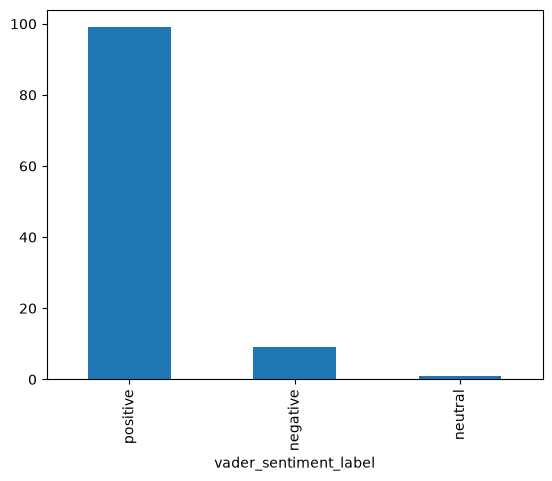

In [ ]:
data2['vader_sentiment_label'].value_counts().plot.bar()

### Transformer Analysis

In [22]:
transformer_pipeline = pipeline("sentiment-analysis")

[transformers] No model was supplied, defaulted to distilbert/distilbert-base-uncased-finetuned-sst-2-english and revision 714eb0f.
Using a pipeline without specifying a model name and revision in production is not recommended.
Loading weights: 100%|██████████| 104/104 [00:00<00:00, 11335.66it/s]


In [ ]:
transformer_labels = []

for review in data2['no_punc_review'].values:
    sentiment_list = transformer_pipeline(review)
    sentiment_label = sentiment_list[0]['label']
    transformer_labels.append(sentiment_label)

# print(transformer_labels)
data2['tranformer_sentiment_label'] = transformer_labels

,Review,Rating,no_punc_review,vader_sentiment_score,vader_sentiment_label,tranformer_sentiment_label
0,nice hotel expensive parking got good deal sta...,4,nice hotel expensive parking got good deal sta...,0.9626,positive,NEGATIVE
1,ok nothing special charge diamond member hilto...,2,ok nothing special charge diamond member hilto...,0.9870,positive,NEGATIVE
2,nice rooms not 4* experience hotel monaco seat...,3,nice rooms not 4star experience hotel monaco s...,0.9921,positive,NEGATIVE
3,"unique, great stay, wonderful time hotel monac...",5,unique great stay wonderful time hotel monaco ...,0.9946,positive,POSITIVE
4,"great stay great stay, went seahawk game aweso...",5,great stay great stay went seahawk game awesom...,0.9907,positive,NEGATIVE


<Axes: xlabel='tranformer_sentiment_label'>

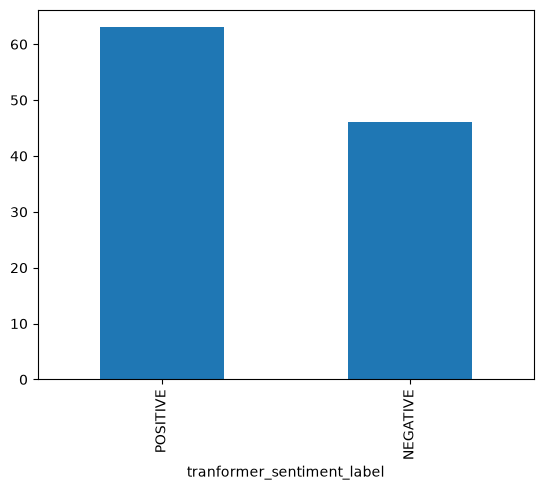

In [30]:
data2['tranformer_sentiment_label'].value_counts().plot.bar()